In [ ]:
!pip install -q gensim datasets pandas

import os, re, json
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/hausa_news_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

required = ["train.csv", "val.csv", "test.csv", "labels.json"]
missing = [f for f in required if not os.path.exists(f)]
print("Working dir:", os.getcwd())
print("Missing files:", missing if missing else "none, ready to go")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 39.1 MB/s eta 0:00:00
Mounted at /content/drive
Working dir: /content/drive/MyDrive/hausa_news_project
Missing files: none, ready to go


In [ ]:
import time, random
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv"); test = pd.read_csv("test.csv")
meta = json.load(open("labels.json"))
id2label = {int(k): v for k, v in meta["id2label"].items()}
label_names = [id2label[i] for i in range(len(id2label))]
NUM_CLASSES = len(label_names)
X_train, y_train = train["text_clean"], train["label_id"].values
X_val,   y_val   = val["text_clean"],   val["label_id"].values
X_test,  y_test  = test["text_clean"],  test["label_id"].values


RESULTS_FILE = "results.json"
try: RESULTS = json.load(open(RESULTS_FILE))
except FileNotFoundError: RESULTS = []

def compute_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": p,
            "macro_recall": r, "macro_f1": f1, "weighted_f1": f1_score(y_true, y_pred, average="weighted")}

def log_result(name, val_metrics, test_metrics=None, notes=""):
    row = {"model": name, "notes": notes, **{f"val_{k}": round(v, 4) for k, v in val_metrics.items()}}
    if test_metrics: row.update({f"test_{k}": round(v, 4) for k, v in test_metrics.items()})
    RESULTS[:] = [r for r in RESULTS if r["model"] != name]
    RESULTS.append(row)
    json.dump(RESULTS, open(RESULTS_FILE, "w"), indent=2)

def full_report(name, y_true, y_pred, X_text, prefix="final"):
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion matrix: {name}\n(colour = row-normalised, numbers = counts)")
    plt.tight_layout(); plt.savefig(f"{prefix}_confusion_matrix.png", dpi=150); plt.show()
    err = pd.DataFrame({"text": X_text.values, "true": [id2label[i] for i in y_true],
                        "pred": [id2label[i] for i in y_pred]})
    err = err[err["true"] != err["pred"]]
    err.to_csv(f"{prefix}_errors.csv", index=False)
    print(f"Misclassified: {len(err)} / {len(y_true)} -> saved {prefix}_errors.csv")
    return err

Device: cuda


In [ ]:
MAX_LEN, MIN_FREQ = 400, 2

def tokenize(t): return re.findall(r"\w+", t.lower())

train_tok = [tokenize(t) for t in X_train]
val_tok   = [tokenize(t) for t in X_val]
test_tok  = [tokenize(t) for t in X_test]

counts = Counter(w for doc in train_tok for w in doc)
itos = ["<pad>", "<unk>"] + [w for w, c in counts.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
print(f"Vocab size (min_freq={MIN_FREQ}): {len(itos)} of {len(counts)} word types")

def encode(docs):
    ids = np.zeros((len(docs), MAX_LEN), dtype=np.int64)
    lens = np.zeros(len(docs), dtype=np.int64)
    for i, doc in enumerate(docs):
        seq = [stoi.get(w, 1) for w in doc[:MAX_LEN]] or [1]
        ids[i, :len(seq)] = seq
        lens[i] = len(seq)
    return torch.tensor(ids), torch.tensor(lens)

Xtr, Ltr = encode(train_tok); Xva, Lva = encode(val_tok); Xte, Lte = encode(test_tok)
ytr, yva, yte = map(torch.tensor, (y_train, y_val, y_test))
print("Shapes:", Xtr.shape, Xva.shape, Xte.shape)
print(f"Train docs truncated at {MAX_LEN} tokens: {np.mean([len(d) > MAX_LEN for d in train_tok])*100:.1f}%")

Vocab size (min_freq=2): 16285 of 29759 word types
Shapes: torch.Size([2219, 400]) torch.Size([317, 400]) torch.Size([637, 400])
Train docs truncated at 400 tokens: 44.5%


In [ ]:
from gensim.models import Word2Vec, FastText

EMB_DIM = 200
W2V_FILE, FT_FILE = "w2v_matrix.pt", "ft_matrix.pt"

def build_matrix(kv, is_fasttext):
    rng = np.random.default_rng(SEED)
    M = rng.normal(0, 0.1, (len(itos), EMB_DIM)).astype("float32")
    M[0] = 0
    hit = 0
    for w, i in stoi.items():
        if i < 2:
            continue

        if is_fasttext or w in kv.key_to_index:
            M[i] = kv.get_vector(w)
            hit += 1
    print(f"Initialised {hit}/{len(itos)-2} words from pretrained vectors")
    return torch.tensor(M)

if os.path.exists(W2V_FILE) and os.path.exists(FT_FILE):
    W2V_MATRIX, FT_MATRIX = torch.load(W2V_FILE), torch.load(FT_FILE)
    print("Loaded cached embedding matrices from Drive")
else:
    t0 = time.time()
    w2v = Word2Vec(sentences=train_tok, vector_size=EMB_DIM, window=5, min_count=2,
                   sg=1, epochs=30, seed=SEED, workers=4)
    ft = FastText(sentences=train_tok, vector_size=EMB_DIM, window=5, min_count=2,
                  sg=1, epochs=30, min_n=3, max_n=6, seed=SEED, workers=4)
    print(f"Embeddings trained in {time.time()-t0:.0f}s")
    W2V_MATRIX = build_matrix(w2v.wv, is_fasttext=False)
    FT_MATRIX  = build_matrix(ft.wv,  is_fasttext=True)
    torch.save(W2V_MATRIX, W2V_FILE); torch.save(FT_MATRIX, FT_FILE)
    for probe in ["kwallon", "gwamna", "cuta", "addini"]:
        if probe in w2v.wv.key_to_index:
            print(probe, "->", [w for w, _ in w2v.wv.most_similar(probe, topn=5)])

Loaded cached embedding matrices from Drive


In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden, num_classes, rnn_type="GRU",
                 emb_matrix=None, freeze_emb=False, dropout=0.4):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if emb_matrix is not None:
            self.emb.weight.data.copy_(emb_matrix)
        self.emb.weight.requires_grad = not freeze_emb
        rnn_cls = nn.GRU if rnn_type == "GRU" else nn.LSTM
        self.rnn = rnn_cls(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * 4, num_classes)

    def forward(self, x, lens):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (torch.arange(x.size(1), device=x.device)[None, :] < lens[:, None]).unsqueeze(-1)
        mx = out.masked_fill(~mask, -1e9).max(1).values
        mean = (out * mask).sum(1) / lens.unsqueeze(1).float()
        return self.fc(self.drop(torch.cat([mx, mean], dim=1)))

@torch.no_grad()
def predict(model, X, L, bs=64):
    model.eval(); preds = []
    for i in range(0, len(X), bs):
        logits = model(X[i:i+bs].to(device), L[i:i+bs].to(device))
        preds.append(logits.argmax(1).cpu())
    return torch.cat(preds).numpy()

def train_model(rnn_type, emb_matrix=None, freeze_emb=False, hidden=128, lr=1e-3,
                epochs=30, patience=5, batch_size=32, verbose=True, seed=SEED):
    set_seed(seed)
    model = RNNClassifier(len(itos), EMB_DIM, hidden, NUM_CLASSES, rnn_type,
                          emb_matrix, freeze_emb).to(device)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-2)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(Xtr, Ltr, ytr), batch_size=batch_size, shuffle=True)
    best_f1, best_state, bad, history = -1, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); total = 0
        for xb, lb, yb in loader:
            xb, lb, yb = xb.to(device), lb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb, lb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); total += loss.item() * len(xb)
        vf1 = f1_score(y_val, predict(model, Xva, Lva), average="macro")
        history.append((ep, total / len(Xtr), vf1))
        if verbose: print(f"  epoch {ep:2d}  train_loss={total/len(Xtr):.4f}  val_macro_F1={vf1:.4f}")
        if vf1 > best_f1:
            best_f1, bad = vf1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f"  early stop at epoch {ep}")
                break
    model.load_state_dict(best_state)
    return model, history

In [ ]:
import re as _re

configs = [
    ("BiGRU  + random init",   "GRU",  None),
    ("BiLSTM + random init",   "LSTM", None),
    ("BiGRU  + Word2Vec init", "GRU",  W2V_MATRIX),
    ("BiLSTM + Word2Vec init", "LSTM", W2V_MATRIX),
    ("BiGRU  + fastText init", "GRU",  FT_MATRIX),
    ("BiLSTM + fastText init", "LSTM", FT_MATRIX),
]
os.makedirs("ckpt", exist_ok=True)
slug = lambda s: _re.sub(r"\W+", "_", s.strip())

trained, histories = {}, {}
for name, rnn_type, mat in configs:
    ck, hf = f"ckpt/{slug(name)}.pt", f"ckpt/{slug(name)}_hist.json"
    if os.path.exists(ck) and os.path.exists(hf):
        model = RNNClassifier(len(itos), EMB_DIM, 128, NUM_CLASSES, rnn_type).to(device)
        model.load_state_dict(torch.load(ck, map_location=device))
        hist = json.load(open(hf))
        print(f"{name:26s} loaded from checkpoint")
    else:
        t0 = time.time()
        model, hist = train_model(rnn_type, emb_matrix=mat, verbose=False)
        torch.save(model.state_dict(), ck)
        json.dump(hist, open(hf, "w"))
        print(f"{name:26s} trained in {time.time()-t0:.0f}s, epochs={len(hist)}")
    m = compute_metrics(y_val, predict(model, Xva, Lva))
    trained[name], histories[name] = model, hist
    log_result(name, m, notes=f"{rnn_type}, emb={'random' if mat is None else 'pretrained (trainable)'}, "
                              f"dim={EMB_DIM}, hidden=128, max_len={MAX_LEN}")
    print(f"   val acc={m['accuracy']:.3f}  macro-F1={m['macro_f1']:.3f}")

BiGRU  + random init       trained in 54s, epochs=17
   val acc=0.842  macro-F1=0.826
BiLSTM + random init       trained in 45s, epochs=17
   val acc=0.817  macro-F1=0.800
BiGRU  + Word2Vec init     trained in 40s, epochs=15
   val acc=0.893  macro-F1=0.883
BiLSTM + Word2Vec init     trained in 42s, epochs=16
   val acc=0.912  macro-F1=0.904
BiGRU  + fastText init     trained in 42s, epochs=16
   val acc=0.899  macro-F1=0.890
BiLSTM + fastText init     trained in 45s, epochs=17
   val acc=0.899  macro-F1=0.890


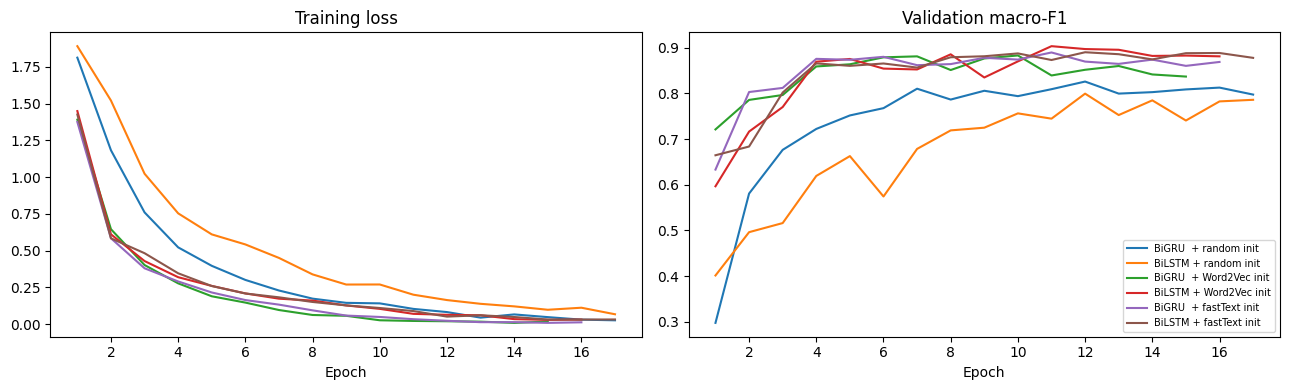

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, hist in histories.items():
    ep = [h[0] for h in hist]
    axes[0].plot(ep, [h[1] for h in hist], label=name)
    axes[1].plot(ep, [h[2] for h in hist], label=name)
axes[0].set_title("Training loss"); axes[1].set_title("Validation macro-F1")
for a in axes: a.set_xlabel("Epoch")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("neural_learning_curves.png", dpi=150); plt.show()

Best neural model by validation macro-F1: BiLSTM + Word2Vec init
VAL : {'accuracy': 0.912, 'macro_precision': 0.906, 'macro_recall': 0.906, 'macro_f1': 0.904, 'weighted_f1': 0.913}
TEST: {'accuracy': 0.879, 'macro_precision': 0.875, 'macro_recall': 0.863, 'macro_f1': 0.864, 'weighted_f1': 0.876}

===== NEURAL: BiLSTM + Word2Vec init =====
               precision    recall  f1-score   support

     business      0.860     0.613     0.715        80
entertainment      0.944     0.850     0.895       100
       health      0.865     0.970     0.914        99
     politics      0.792     0.950     0.864       100
     religion      0.893     0.929     0.911        99
       sports      0.990     1.000     0.995       100
   technology      0.782     0.729     0.754        59

     accuracy                          0.879       637
    macro avg      0.875     0.863     0.864       637
 weighted avg      0.882     0.879     0.876       637



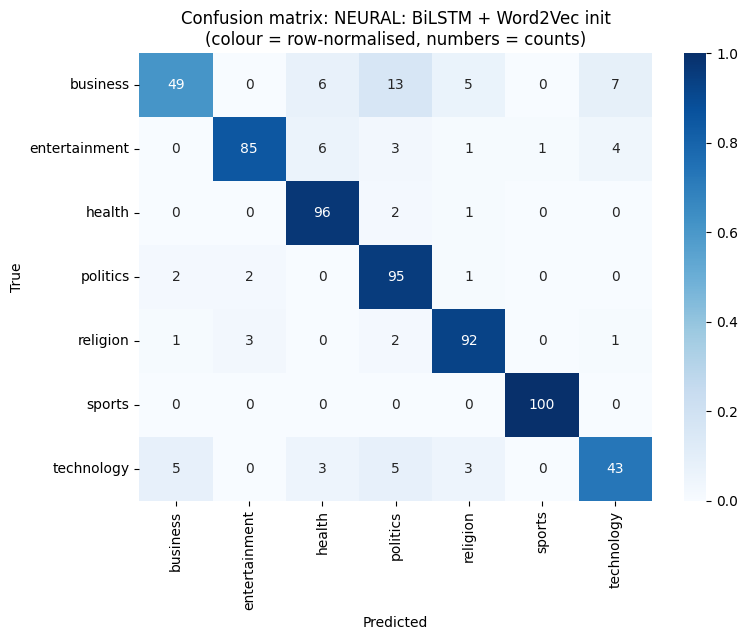

Misclassified: 77 / 637 -> saved neural_errors.csv


,model,notes,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_weighted_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1
0,TFIDF-word + LogReg,baseline,0.9180,0.9125,0.9122,0.9115,0.9181,NaN,NaN,NaN,NaN,NaN
1,TFIDF-word + LinearSVM,baseline,0.9054,0.8981,0.8965,0.8968,0.9053,NaN,NaN,NaN,NaN,NaN
2,TFIDF-word + CompNB,baseline,0.9085,0.9044,0.8939,0.8971,0.9072,NaN,NaN,NaN,NaN,NaN
3,TFIDF-char + LinearSVM,baseline,0.8991,0.8908,0.8915,0.8906,0.8994,NaN,NaN,NaN,NaN,NaN
4,TFIDF-word+char + LinearSVM,baseline,0.9085,0.9014,0.9022,0.9011,0.9089,NaN,NaN,NaN,NaN,NaN
5,TFIDF-word + LinearSVM (balanced),baseline,0.9085,0.9017,0.9035,0.9022,0.9087,NaN,NaN,NaN,NaN,NaN
6,BASELINE: TFIDF word+char + LinearSVM (C=1.0),final baseline,0.9085,0.9014,0.9022,0.9011,0.9089,0.8917,0.8845,0.8788,0.8803,0.8902
7,BiGRU + random init,"GRU, emb=random, dim=200, hidden=128, max_len=400",0.8423,0.8267,0.8266,0.8260,0.8423,NaN,NaN,NaN,NaN,NaN
8,BiLSTM + random init,"LSTM, emb=random, dim=200, hidden=128, max_len...",0.8170,0.8063,0.7993,0.7995,0.8154,NaN,NaN,NaN,NaN,NaN
9,BiGRU + Word2Vec init,"GRU, emb=pretrained (trainable), dim=200, hidd...",0.8927,0.8859,0.8888,0.8832,0.8955,NaN,NaN,NaN,NaN,NaN


In [ ]:
best_name = max(trained, key=lambda n: max(h[2] for h in histories[n]))
best_model = trained[best_name]
print("Best neural model by validation macro-F1:", best_name)

val_m = compute_metrics(y_val, predict(best_model, Xva, Lva))
test_pred = predict(best_model, Xte, Lte)
test_m = compute_metrics(y_test, test_pred)

final_name = f"NEURAL: {best_name.strip()}"
log_result(final_name, val_m, test_m, notes="best neural model, test evaluated once")
print("VAL :", {k: round(v, 3) for k, v in val_m.items()})
print("TEST:", {k: round(v, 3) for k, v in test_m.items()})

errors_neural = full_report(final_name, y_test, test_pred, X_test, prefix="neural")
torch.save(best_model.state_dict(), "best_neural.pt")

pd.DataFrame(RESULTS)

In [ ]:
SEEDS = [1, 2, 3]
rows = []
for name, rnn_type, mat in [("BiLSTM + Word2Vec init", "LSTM", W2V_MATRIX),
                            ("BiGRU  + fastText init", "GRU", FT_MATRIX),
                            ("BiGRU  + random init",   "GRU", None)]:
    for s in SEEDS:
        m_, _ = train_model(rnn_type, emb_matrix=mat, seed=s, verbose=False)
        rows.append({"model": name, "seed": s,
                     "val_macro_f1":  f1_score(y_val,  predict(m_, Xva, Lva), average="macro"),
                     "test_macro_f1": f1_score(y_test, predict(m_, Xte, Lte), average="macro")})
        print(f"{name:26s} seed={s}  val={rows[-1]['val_macro_f1']:.4f}  test={rows[-1]['test_macro_f1']:.4f}")

seed_df = pd.DataFrame(rows)
seed_df.to_csv("neural_seed_runs.csv", index=False)
print(seed_df.groupby("model")[["val_macro_f1", "test_macro_f1"]].agg(["mean", "std"]).round(4))


mf, _ = train_model("LSTM", emb_matrix=W2V_MATRIX, freeze_emb=True, verbose=False)
print("Frozen W2V BiLSTM val macro-F1:", round(f1_score(y_val, predict(mf, Xva, Lva), average="macro"), 4))

BiLSTM + Word2Vec init     seed=1  val=0.8821  test=0.8574
BiLSTM + Word2Vec init     seed=2  val=0.9064  test=0.8688
BiLSTM + Word2Vec init     seed=3  val=0.9085  test=0.8736
BiGRU  + fastText init     seed=1  val=0.8975  test=0.8741
BiGRU  + fastText init     seed=2  val=0.8961  test=0.8799
BiGRU  + fastText init     seed=3  val=0.8781  test=0.8631
BiGRU  + random init       seed=1  val=0.8307  test=0.8317
BiGRU  + random init       seed=2  val=0.8179  test=0.8131
BiGRU  + random init       seed=3  val=0.8209  test=0.7961
                       val_macro_f1         test_macro_f1        
                               mean     std          mean     std
model                                                            
BiGRU  + fastText init       0.8906  0.0108        0.8724  0.0085
BiGRU  + random init         0.8232  0.0067        0.8137  0.0178
BiLSTM + Word2Vec init       0.8990  0.0147        0.8666  0.0084
Frozen W2V BiLSTM val macro-F1: 0.8747
